# EGT309 Project – Task 1: Exploratory Data Analysis (EDA)

## Predicting `maintenance_required` from machine sensor readings

**Business objective (from the Problem Statement).** The AI Manufacturing Analytics team needs an alert
system that flags when a machine is due for maintenance, so that unscheduled downtime is minimised.
The dataset contains sensor readings from **50 machines**, together with several **derived columns**.
The target variable is **`maintenance_required`** (0 = No, 1 = Yes).

**Goal of this notebook.** Understand the data well enough to design the machine-learning pipeline in
Task 2: find data-quality problems and decide how to fix them, discover which features relate to the
target (and why), and turn these findings into concrete decisions on cleaning, imputation, feature
engineering, model choice and evaluation metrics.

**How to read this notebook.** Every section follows the same pattern:

> **Purpose** – why the step is done → **Code / output** → **Interpretation & conclusion** – what the
> statistics mean and how they affect the pipeline.

## EDA process outline

| # | Step | Purpose |
|---|------|---------|
| 1 | Setup | Load libraries and define all configuration (paths, column groups, colours) in one place. |
| 2 | Load data & first look | Confirm the file loads correctly; check size, data types and summary statistics. |
| 3 | Schema validation | Check every column against the data dictionary in the Problem Statement. |
| 4 | Data quality | Duplicates, timestamp format, invalid values, missing values, inconsistencies and outliers. |
| 5 | Target variable | Measure class balance – this drives the choice of metrics and data splitting. |
| 6 | Univariate analysis | Understand the shape of each feature on its own. |
| 7 | Bivariate analysis | Measure how each feature relates to `maintenance_required`. |
| 8 | Multivariate analysis | Correlations between features and the joint behaviour of the key sensors. |
| 9 | Derived columns & target leakage | Find out how the target is constructed and which columns leak it. |
| 10 | Temporal & machine-level patterns | Check whether time or machine identity carry signal (affects splitting and features). |
| 11 | Feature relevance | Rank features by mutual information with the target. |
| 12 | Imputation | Compare imputation techniques for the missing temperatures and apply the chosen one. |
| 13 | Feature engineering | Engineered features recommended for the pipeline, with justification. |
| 14 | Summary of key findings | The findings and the decisions they lead to for Task 2. |

## 1. Setup

**Purpose.** Import the libraries and keep every configurable value (file path, column groups, random
seed, colours) in a single cell, so the analysis is reproducible and easy to change.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (enables IterativeImputer)
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.tree import DecisionTreeClassifier, export_text

# ---------------- Configuration ----------------
DATA_PATH = Path("data") / "proj_machine_readings.csv"
TIMESTAMP_FORMAT = "%d/%m/%Y %H:%M"  # day-first; verified in Section 4.2
RANDOM_STATE = 42
TARGET = "maintenance_required"

SENSOR_COLS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]
DERIVED_COLS = ["machine_status", "anomaly_flag", "predicted_remaining_life",
                "failure_type", "downtime_risk"]
FAILURE_TYPES = ["Normal", "Vibration Issue", "Overheating", "Pressure Drop", "Electrical Fault"]

# ---------------- Plot style ----------------
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # colour-blind-checked categorical slots
INK, INK_2, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
TARGET_COLORS = {0: BLUE, 1: ORANGE}
TARGET_LABELS = {0: "No maintenance (0)", 1: "Maintenance required (1)"}
DIVERGING_CMAP = LinearSegmentedColormap.from_list("blue_grey_red", [BLUE, "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
# ---------------- Reusable helper functions ----------------
def maintenance_rate(data: pd.DataFrame, by) -> pd.DataFrame:
    """Return row count and % of rows needing maintenance for each group of `by`."""
    return (data.groupby(by, observed=True)[TARGET]
                .agg(rows="size", maintenance_rate="mean")
                .assign(maintenance_rate=lambda t: (t["maintenance_rate"] * 100).round(2)))


def iqr_bounds(series: pd.Series, k: float = 1.5) -> tuple:
    """Tukey fences: values outside (Q1 - k*IQR, Q3 + k*IQR) are flagged as outliers."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def rank_biserial(x_pos: pd.Series, x_neg: pd.Series) -> tuple:
    """Mann-Whitney U test plus rank-biserial effect size r in [-1, 1].
    r > 0 means the maintenance-required group tends to have larger values."""
    u_stat, p_value = stats.mannwhitneyu(x_pos, x_neg, alternative="two-sided")
    r = 2 * u_stat / (len(x_pos) * len(x_neg)) - 1
    return p_value, r


def chi_square(a: pd.Series, b: pd.Series) -> tuple:
    """Chi-square test of independence between two categorical series; returns (chi2, p, dof)."""
    chi2, p_value, dof, _ = stats.chi2_contingency(pd.crosstab(a, b))
    return chi2, p_value, dof


def add_reference_line(ax, value, label, axis="y"):
    """Draw a dashed reference line with a short text label."""
    line = ax.axhline if axis == "y" else ax.axvline
    line(value, color=INK_2, linestyle="--", linewidth=1)
    if axis == "y":
        ax.annotate(label, xy=(1, value), xycoords=("axes fraction", "data"), xytext=(-4, 4),
                    textcoords="offset points", ha="right", va="bottom", fontsize=8, color=INK_2)
    else:
        ax.annotate(label, xy=(value, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
                    textcoords="offset points", ha="left", va="top", fontsize=8, color=INK_2)

## 2. Load data & first look

**Purpose.** Confirm the CSV loads correctly and get a first view of its size, column types, missing
values and value ranges. This tells us which columns need closer inspection.

In [3]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 100,000   Columns: 13


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,1/1/2025 0:00,39,NaN,-28.6500,79.9600,3.7300,2.1600,1,0,106,Normal,0.0000,0
1,1/1/2025 0:01,29,68.1900,57.2800,35.9400,3.6400,0.6900,1,0,320,Normal,0.0000,0
2,1/1/2025 0:02,15,98.9400,50.2000,72.0600,1.0000,2.4900,1,1,19,Normal,1.0000,1
3,1/1/2025 0:03,43,90.9100,37.6500,30.3400,3.1500,4.9600,1,1,10,Normal,1.0000,1
4,1/1/2025 0:04,8,72.3200,40.6900,56.7100,2.6800,0.6300,2,0,65,Vibration Issue,0.0000,1


In [4]:
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(),
})
overview

,dtype,non_null,missing,missing_%,unique_values
timestamp,str,100000,0,0.0000,100000
machine_id,int64,100000,0,0.0000,50
temperature,float64,86000,14000,14.0000,5713
vibration,float64,100000,0,0.0000,12065
humidity,float64,100000,0,0.0000,5001
pressure,float64,100000,0,0.0000,401
energy_consumption,float64,100000,0,0.0000,451
machine_status,int64,100000,0,0.0000,3
anomaly_flag,int64,100000,0,0.0000,2
predicted_remaining_life,int64,100000,0,0.0000,499


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
machine_id,"100,000.0000",25.4993,14.3894,1.0000,13.0000,25.0000,38.0000,50.0000
temperature,"86,000.0000",75.0344,10.0363,35.5500,68.2800,75.0900,81.7800,121.9400
vibration,"100,000.0000",43.3242,29.1343,-106.9800,37.2200,48.6350,59.2500,113.8000
humidity,"100,000.0000",54.9954,14.4380,30.0000,42.5200,54.9800,67.5000,80.0000
pressure,"100,000.0000",3.0004,1.1524,1.0000,2.0000,3.0100,4.0000,5.0000
energy_consumption,"100,000.0000",2.7471,1.2979,0.5000,1.6300,2.7400,3.8700,5.0000
machine_status,"100,000.0000",1.0021,0.4462,0.0000,1.0000,1.0000,1.0000,2.0000
anomaly_flag,"100,000.0000",0.0892,0.2850,0.0000,0.0000,0.0000,0.0000,1.0000
predicted_remaining_life,"100,000.0000",234.2692,150.0631,1.0000,97.0000,230.0000,365.0000,499.0000
downtime_risk,"100,000.0000",0.0892,0.2850,0.0000,0.0000,0.0000,0.0000,1.0000


**Interpretation & conclusion.**

* The file has **100,000 rows and 13 columns**. `timestamp` and `failure_type` are text; everything else is numeric.
* **`temperature` is the only column with missing values (14,000 rows, 14.00%)**
* **`vibration` has a negative minimum (-106.98)**. Vibration level in mm/s is a magnitude and cannot be negative
* `machine_id` has 50 unique values, matching the 50 machines in the Problem Statement. Although it is stored as an integer, the Problem Statement says it is **a category label, not a quantity**, so its mean/std are meaningless.
* `downtime_risk` is documented as a 0–1 risk score but its 25th, 50th and 75th percentiles are all 0, and its mean (0.0892) is almost identical to `anomaly_flag` (0.0892)
* The target mean is 0.1970, i.e. about **19.7% of readings require maintenance**

## 3. Schema validation against the data dictionary

**Purpose.** The Problem Statement documents what each column means. Here every column is checked against
a rule derived from that documentation (allowed values, physical limits). Any rule that fails points to a
data-quality problem that the pipeline must handle.

*Note:* the Problem Statement does not give numeric ranges for the sensors, so physically sensible limits
are used (e.g. vibration level and energy cannot be negative, humidity must be within 0–100%).

In [6]:
def validate_schema(data: pd.DataFrame) -> pd.DataFrame:
    """Check each column against a rule derived from the Problem Statement's data dictionary."""
    parsed_ts = pd.to_datetime(data["timestamp"], format=TIMESTAMP_FORMAT, errors="coerce")
    temp = data["temperature"]
    checks = [
        ("timestamp", "parses as D/M/YYYY H:MM", parsed_ts.isna()),
        ("machine_id", "label between 1 and 50", ~data["machine_id"].between(1, 50)),
        ("temperature", "physically plausible: 0-200 °C (missing ignored)", temp.notna() & ~temp.between(0, 200)),
        ("vibration", "vibration level (mm/s) is non-negative", data["vibration"] < 0),
        ("humidity", "relative humidity within 0-100 %", ~data["humidity"].between(0, 100)),
        ("pressure", "operating pressure (bar) is positive", data["pressure"] <= 0),
        ("energy_consumption", "energy used (kWh) is non-negative", data["energy_consumption"] < 0),
        ("machine_status", "one of {0 idle, 1 running, 2 failure}", ~data["machine_status"].isin([0, 1, 2])),
        ("anomaly_flag", "one of {0, 1}", ~data["anomaly_flag"].isin([0, 1])),
        ("predicted_remaining_life", "remaining life (hours) is non-negative", data["predicted_remaining_life"] < 0),
        ("failure_type", "one of the 5 documented labels", ~data["failure_type"].isin(FAILURE_TYPES)),
        ("downtime_risk", "risk score within [0, 1]", ~data["downtime_risk"].between(0, 1)),
        (TARGET, "one of {0, 1}", ~data[TARGET].isin([0, 1])),
    ]
    return pd.DataFrame([
        {"column": col, "rule": rule, "violations": int(bad.sum()),
         "status": "PASS" if bad.sum() == 0 else "FAIL"}
        for col, rule, bad in checks
    ])


validate_schema(df_raw)

,column,rule,violations,status
0,timestamp,parses as D/M/YYYY H:MM,0,PASS
1,machine_id,label between 1 and 50,0,PASS
2,temperature,physically plausible: 0-200 °C (missing ignored),0,PASS
3,vibration,vibration level (mm/s) is non-negative,6703,FAIL
4,humidity,relative humidity within 0-100 %,0,PASS
5,pressure,operating pressure (bar) is positive,0,PASS
6,energy_consumption,energy used (kWh) is non-negative,0,PASS
7,machine_status,"one of {0 idle, 1 running, 2 failure}",0,PASS
8,anomaly_flag,"one of {0, 1}",0,PASS
9,predicted_remaining_life,remaining life (hours) is non-negative,0,PASS


**Interpretation & conclusion.**

* **Only `vibration` fails** its rule: **6,703 rows (6.70%) are negative.** All other columns hold values allowed by the data dictionary.
* All `failure_type` labels exactly match the five documented labels (no typos, extra spaces or case differences), and every timestamp parses in the day-first format.
* `temperature` values that are present are physically plausible; the problem with temperature is *missing* values, not wrong ones.

## 4. Data quality

### 4.1 Duplicates

**Purpose.** Duplicate rows would over-weight some readings and can leak identical rows into both the training
and test sets. We check for exact duplicate rows and for duplicate (machine, timestamp) pairs.

In [7]:
print(f"Exact duplicate rows:                 {df_raw.duplicated().sum():,}")
print(f"Duplicate (machine_id, timestamp):    {df_raw.duplicated(subset=['machine_id', 'timestamp']).sum():,}")
print(f"Duplicate timestamps (any machine):   {df_raw['timestamp'].duplicated().sum():,}")

Exact duplicate rows:                 0
Duplicate (machine_id, timestamp):    0
Duplicate timestamps (any machine):   0


**Conclusion.** There are **no duplicates** of any kind. Every timestamp is unique, i.e. **exactly one reading
(from one machine) is recorded per minute**. No de-duplication step is needed.

### 4.2 Timestamp format

**Purpose.** Dates such as `1/2/2025` are ambiguous (1 Feb or 2 Jan?). Parsing them with the wrong format
silently produces wrong dates, which would break any time-based feature or time-based data split.

In [8]:
# Replace every digit with 9 to reveal the text pattern of the timestamps.
patterns = df_raw["timestamp"].str.replace(r"\d", "9", regex=True).value_counts()
display(patterns.rename("rows").to_frame())

date_parts = df_raw["timestamp"].str.extract(r"^(\d+)/(\d+)/(\d+)").astype(int)
print(f"Largest 1st component: {date_parts[0].max()}  -> can only be the DAY")
print(f"Largest 2nd component: {date_parts[1].max()}  -> MONTH (Jan-Mar)")
month_first = pd.to_datetime(df_raw["timestamp"], format="%m/%d/%Y %H:%M", errors="coerce")
print(f"Rows that fail if parsed month-first: {month_first.isna().sum():,}")

,rows
timestamp,
99/9/9999 99:99,35320
99/9/9999 9:99,25800
9/9/9999 99:99,22680
9/9/9999 9:99,16200


Largest 1st component: 31  -> can only be the DAY
Largest 2nd component: 3  -> MONTH (Jan-Mar)
Rows that fail if parsed month-first: 50,400


In [9]:
timestamps = pd.to_datetime(df_raw["timestamp"], format=TIMESTAMP_FORMAT)
gaps = timestamps.diff().dropna()
print(f"First reading:  {timestamps.min()}")
print(f"Last reading:   {timestamps.max()}")
print(f"Span:           {timestamps.max() - timestamps.min()}")
print(f"Sorted in time: {timestamps.is_monotonic_increasing}")
print("Gap between consecutive rows:")
display(gaps.value_counts().rename("rows").to_frame())
print("Readings per machine:")
display(df_raw["machine_id"].value_counts().describe().to_frame("readings_per_machine").T)

First reading:  2025-01-01 00:00:00
Last reading:   2025-03-11 10:39:00
Span:           69 days 10:39:00
Sorted in time: True
Gap between consecutive rows:


,rows
timestamp,
0 days 00:01:00,99999


Readings per machine:


,count,mean,std,min,25%,50%,75%,max
readings_per_machine,50.0000,"2,000.0000",51.6732,"1,906.0000","1,956.2500","2,002.5000","2,042.5000","2,092.0000"


**Interpretation & conclusion.**

* The first number goes up to 31 and the second only up to 3, so the format is **day-first (`D/M/YYYY H:MM`)**.
  Parsing month-first fails on more than half of the rows, so the pipeline must parse with the explicit format
  `%d/%m/%Y %H:%M` rather than relying on automatic date detection.
* Readings cover **1 Jan 2025 00:00 to 11 Mar 2025 10:39** (~69.4 days) with **exactly one-minute spacing and no gaps**.
* Each minute, one of the 50 machines is sampled, giving **~2,000 readings per machine (min 1,906, max 2,092)**.
  The dataset is balanced across machines, so no single machine dominates the analysis.

In [10]:
# Working copy used for the rest of the EDA (df_raw stays untouched for reference).
df = df_raw.copy()
df["timestamp"] = timestamps

### 4.3 Invalid values – negative vibration

**Purpose.** Section 3 found 6,703 negative vibration readings. We must decide whether they are
(a) genuine but unusual readings, (b) random noise that should be removed, or (c) a systematic recording error
that can be corrected. The decision changes how many rows we keep and how vibration is fed to the model.

In [11]:
is_negative = df_raw["vibration"] < 0
positive_vals = df_raw.loc[~is_negative, "vibration"]
negative_mags = df_raw.loc[is_negative, "vibration"].abs()

print(f"Negative readings: {is_negative.sum():,} ({is_negative.mean():.2%} of rows)")
display(pd.DataFrame({"positive readings": positive_vals.describe(),
                      "|negative readings|": negative_mags.describe()}).T)

ks = stats.ks_2samp(negative_mags, positive_vals)
print(f"Kolmogorov-Smirnov test, |negative| vs positive: D = {ks.statistic:.4f}, p-value = {ks.pvalue:.4f}")

Negative readings: 6,703 (6.70% of rows)


,count,mean,std,min,25%,50%,75%,max
positive readings,"93,297.0000",50.0231,14.9540,0.1000,39.9600,49.9600,60.1100,113.8000
|negative readings|,"6,703.0000",49.9146,15.2465,0.0200,40.0250,50.0200,60.0500,106.9800


Kolmogorov-Smirnov test, |negative| vs positive: D = 0.0099, p-value = 0.5750


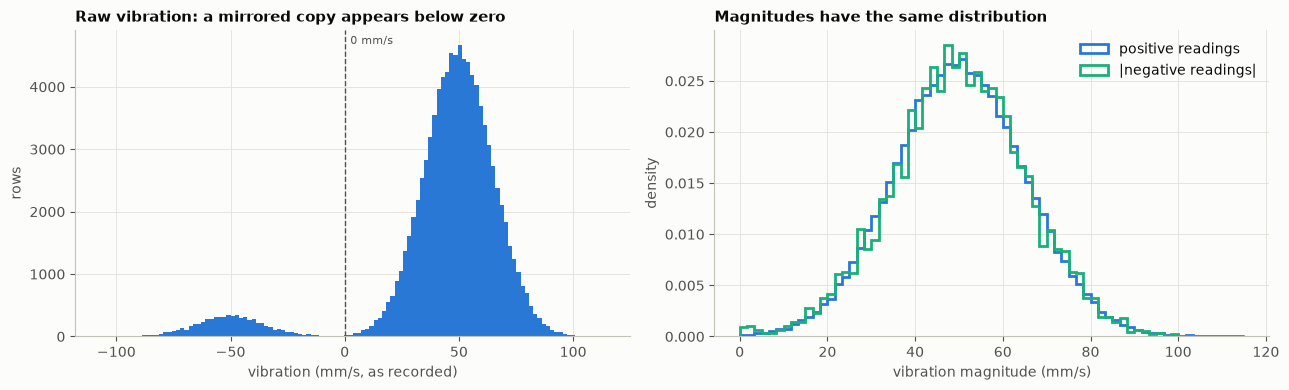

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df_raw["vibration"], bins=120, color=BLUE)
axes[0].set(title="Raw vibration: a mirrored copy appears below zero",
            xlabel="vibration (mm/s, as recorded)", ylabel="rows")
add_reference_line(axes[0], 0, "0 mm/s", axis="x")

bins = np.linspace(0, 115, 70)
axes[1].hist(positive_vals, bins=bins, density=True, histtype="step", linewidth=2,
             color=BLUE, label="positive readings")
axes[1].hist(negative_mags, bins=bins, density=True, histtype="step", linewidth=2,
             color=AQUA, label="|negative readings|")
axes[1].set(title="Magnitudes have the same distribution",
            xlabel="vibration magnitude (mm/s)", ylabel="density")
axes[1].legend()
plt.tight_layout()
plt.show()

In [13]:
# Is the negative sign related to the machine, its status, or the target?
sign = np.where(is_negative, "negative", "positive")
display(pd.DataFrame({
    "maintenance_rate_%": df_raw.groupby(sign)[TARGET].mean() * 100,
    "anomaly_rate_%": df_raw.groupby(sign)["anomaly_flag"].mean() * 100,
    "failure_status_%": df_raw.groupby(sign)["machine_status"].apply(lambda s: (s == 2).mean() * 100),
}).round(2))
chi2, p, dof = chi_square(df_raw["machine_id"], is_negative)
print(f"Chi-square, negative sign vs machine_id: chi2 = {chi2:.2f}, dof = {dof}, p-value = {p:.4f}")

# How does the anomaly_flag label treat large negative values?
vib_band = pd.cut(df_raw["vibration"], bins=[-np.inf, -80, 0, 80, np.inf],
                  labels=["< -80", "-80 to 0", "0 to 80", "> 80"], right=True)
display(df_raw.groupby(vib_band, observed=True)["anomaly_flag"]
              .agg(rows="size", anomaly_rate="mean")
              .assign(anomaly_rate=lambda t: (t["anomaly_rate"] * 100).round(2)))

,maintenance_rate_%,anomaly_rate_%,failure_status_%
negative,19.5900,8.8300,10.0900
positive,19.7000,8.9200,10.0500


Chi-square, negative sign vs machine_id: chi2 = 49.93, dof = 49, p-value = 0.4361


,rows,anomaly_rate
vibration,,
< -80,151,100.0000
-80 to 0,6552,6.7300
0 to 80,91164,6.7900
> 80,2133,100.0000


**Interpretation & conclusion.**

* **The negative values are a sign error, not noise.** The magnitudes of the negative readings have the same
  distribution as the positive readings (means 49.91 vs 50.02, std 15.25 vs 14.95). The Kolmogorov–Smirnov test
  finds no difference (D ≈ 0.01, p ≈ 0.58; a large p-value means we cannot tell the two distributions apart).
* The sign is **unrelated to the machine** (chi-square p > 0.05), the target, the anomaly rate or the failure
  status, i.e. it looks like a random recording/sign-convention error.
* The `anomaly_flag` label itself treats **large negative values (< -80) exactly like large positive values (> 80)**:
  **100%** of both are flagged as anomalies, while the moderate bands (-80 to 0 and 0 to 80) have the same low anomaly
  rate (6.73% vs 6.79%). This confirms that the label was produced from the *magnitude* of vibration.
* **Decision:** keep all rows and use the absolute value, `vibration = |vibration|`. Dropping the rows would
  throw away 6.7% of the data for no reason, and keeping the sign would split one physical signal into two
  unrelated-looking groups that linear models cannot handle.

In [14]:
df["vibration"] = df_raw["vibration"].abs()
print(f"Negative vibration values remaining: {(df['vibration'] < 0).sum()}")

Negative vibration values remaining: 0


### 4.4 Missing values – temperature

**Purpose.** The right imputation technique depends on *why* values are missing. If the gaps are random
(MCAR – Missing Completely At Random), simple imputation is unbiased. If missingness depends on other columns or
the target, it carries information and must be handled more carefully. We test whether missing temperature is
related to any other column.

In [15]:
temp_missing = df["temperature"].isna()
print(f"Missing temperature: {temp_missing.sum():,} rows ({temp_missing.mean():.2%})")

tests = []
for col in [TARGET, "machine_status", "anomaly_flag", "failure_type", "machine_id"]:
    chi2, p, dof = chi_square(temp_missing, df[col])
    tests.append({"compared_with": col, "test": "chi-square", "statistic": chi2, "p_value": p})
for col in ["vibration", "humidity", "pressure", "energy_consumption", "predicted_remaining_life"]:
    u_stat, p = stats.mannwhitneyu(df.loc[temp_missing, col], df.loc[~temp_missing, col])
    tests.append({"compared_with": col, "test": "Mann-Whitney U", "statistic": u_stat, "p_value": p})

mcar_tests = pd.DataFrame(tests)
bonferroni_alpha = 0.05 / len(mcar_tests)
mcar_tests["significant_after_bonferroni"] = mcar_tests["p_value"] < bonferroni_alpha
print(f"Bonferroni-corrected significance level: 0.05 / {len(mcar_tests)} = {bonferroni_alpha:.4f}")
mcar_tests

Missing temperature: 14,000 rows (14.00%)
Bonferroni-corrected significance level: 0.05 / 10 = 0.0050


,compared_with,test,statistic,p_value,significant_after_bonferroni
0,maintenance_required,chi-square,1.0203,0.3124,False
1,machine_status,chi-square,0.3778,0.8279,False
2,anomaly_flag,chi-square,0.3985,0.5279,False
3,failure_type,chi-square,3.9570,0.4119,False
4,machine_id,chi-square,36.8727,0.8988,False
5,vibration,Mann-Whitney U,"605,010,713.0000",0.3419,False
6,humidity,Mann-Whitney U,"601,171,725.5000",0.7937,False
7,pressure,Mann-Whitney U,"607,456,817.5000",0.0849,False
8,energy_consumption,Mann-Whitney U,"594,959,326.0000",0.0262,False
9,predicted_remaining_life,Mann-Whitney U,"602,807,546.0000",0.7988,False


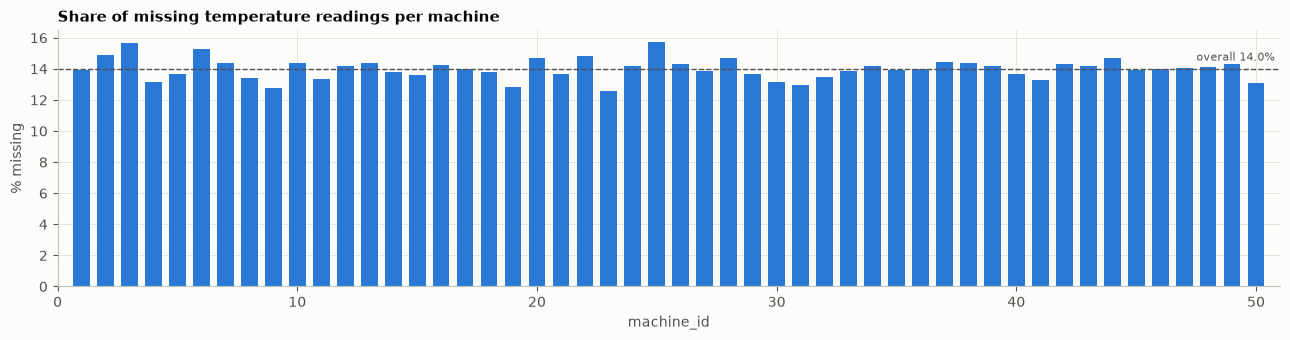

,rows,maintenance_rate
temperature_missing,,
False,86000,19.7500
True,14000,19.3800


In [16]:
missing_by_machine = temp_missing.groupby(df["machine_id"]).mean() * 100
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(missing_by_machine.index, missing_by_machine.values, color=BLUE, width=0.7)
add_reference_line(ax, temp_missing.mean() * 100, f"overall {temp_missing.mean():.1%}")
ax.set(title="Share of missing temperature readings per machine",
       xlabel="machine_id", ylabel="% missing", xlim=(0, 51))
plt.tight_layout()
plt.show()
display(maintenance_rate(df, temp_missing.rename("temperature_missing")))

**Interpretation & conclusion.**

* Missing temperature is **not related to the target** (19.38% vs 19.75% maintenance rate, chi-square p ≈ 0.31),
  nor to machine status, anomaly flag, failure type or machine (all p > 0.05). Every machine has between ~12.6%
  and ~15.7% missing, scattered around the overall 14%.
* Only `energy_consumption` gives p ≈ 0.03 on its own. Because 10 tests were run, the chance of at least one
  false alarm at the 5% level is high; after the **Bonferroni correction** (α = 0.005) **no test is significant**.
  The difference in energy medians is also negligible in practical terms.
* **Conclusion: temperature is Missing Completely At Random (MCAR).** Dropping these rows would lose 14% of the
  data for no benefit, so we **impute** instead. Section 12 compares imputation techniques.

### 4.5 Consistency between derived columns

**Purpose.** Derived columns should agree with each other (e.g. a failure type should only appear when the machine
is in failure). Disagreements reveal unreliable or redundant columns.

In [17]:
print("downtime_risk (rounded to 0/1) vs anomaly_flag:")
display(pd.crosstab(df["downtime_risk"].round(0), df["anomaly_flag"]))
fractional_risk = df[(df["downtime_risk"] > 0) & (df["downtime_risk"] < 1)]
print(f"Rows with a fractional downtime_risk: {len(fractional_risk)}")
display(fractional_risk[["downtime_risk", "anomaly_flag", "machine_status", "failure_type", TARGET]])

downtime_risk (rounded to 0/1) vs anomaly_flag:


anomaly_flag,0,1
downtime_risk,,
0.0000,91084,0
1.0000,0,8916


Rows with a fractional downtime_risk: 12


,downtime_risk,anomaly_flag,machine_status,failure_type,maintenance_required
2626,0.9800,1,2,Pressure Drop,1
16461,0.9900,1,1,Normal,1
24013,0.9700,1,1,Normal,1
28277,0.9900,1,1,Normal,1
28784,0.9800,1,1,Normal,1
34937,0.9200,1,1,Normal,1
40156,0.9400,1,1,Normal,1
49903,0.9700,1,1,Normal,1
59683,0.8800,1,1,Normal,1
62659,0.9300,1,2,Vibration Issue,1


In [18]:
print("failure_type vs machine_status:")
pd.crosstab(df["failure_type"], df["machine_status"], margins=True)

failure_type vs machine_status:


machine_status,0,1,2,All
failure_type,,,,
Electrical Fault,0,0,1014,1014
Normal,9852,80091,1956,91899
Overheating,0,0,1989,1989
Pressure Drop,0,0,1969,1969
Vibration Issue,0,0,3129,3129
All,9852,80091,10057,100000


**Interpretation & conclusion.**

* **`downtime_risk` is a near-copy of `anomaly_flag`.** It is 0 exactly when there is no anomaly and 1 (or 0.88–0.99
  in just 12 rows, all of which are anomalies) when there is. It adds no new information and would only duplicate
  the anomaly signal → **drop it** from the features.
* **A non-Normal `failure_type` only ever appears when `machine_status = 2` (failure).** It describes *what went wrong
  after* the failure, so it is not available in advance for a *preventive* alert.
* **1,956 failure rows are labelled `Normal`**, so `failure_type` is also incomplete: it cannot be relied on to
  identify failures.

### 4.6 Outliers

**Purpose.** Outliers can be measurement errors (remove or cap them) or real extreme conditions (keep them, as they
may be the very events we want to predict). We flag them with Tukey's IQR fences and check how they relate to the target.

In [19]:
outlier_rows = []
for col in SENSOR_COLS:
    values = df[col].dropna()
    low, high = iqr_bounds(values)
    is_low, is_high = df[col] < low, df[col] > high
    outlier_rows.append({
        "feature": col, "lower_fence": low, "upper_fence": high,
        "n_below": int(is_low.sum()), "n_above": int(is_high.sum()),
        "maint_rate_below_%": df.loc[is_low, TARGET].mean() * 100 if is_low.any() else np.nan,
        "maint_rate_above_%": df.loc[is_high, TARGET].mean() * 100 if is_high.any() else np.nan,
    })
pd.DataFrame(outlier_rows).round(2)

,feature,lower_fence,upper_fence,n_below,n_above,maint_rate_below_%,maint_rate_above_%
0,temperature,48.0300,102.0300,351,298,15.1000,100.0000
1,vibration,9.7700,90.3000,364,350,17.8600,100.0000
2,humidity,5.0500,104.9700,0,0,NaN,NaN
3,pressure,-1.0000,7.0000,0,0,NaN,NaN
4,energy_consumption,-1.7300,7.2300,0,0,NaN,NaN


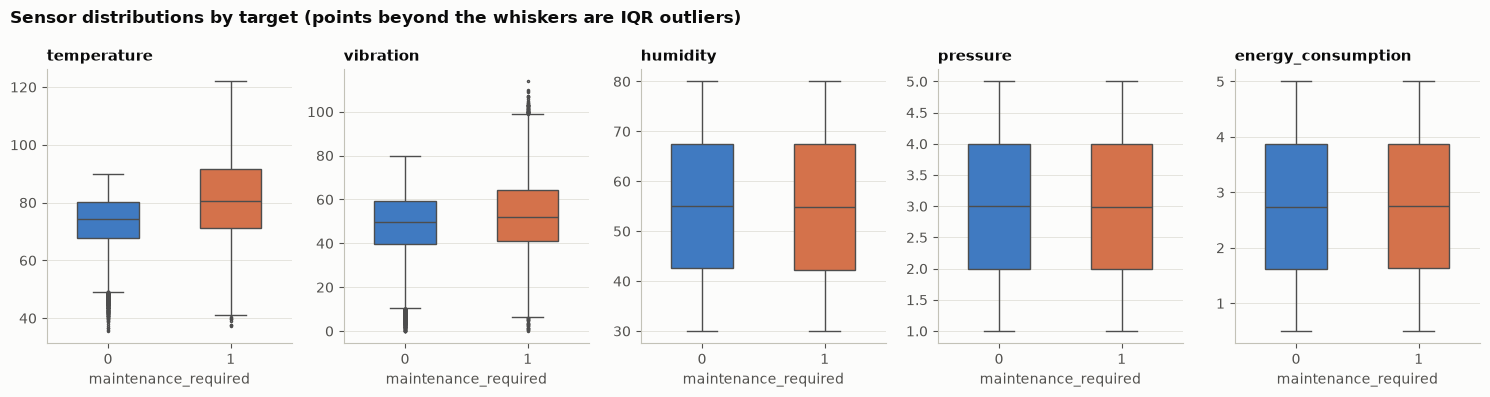

In [20]:
fig, axes = plt.subplots(1, len(SENSOR_COLS), figsize=(15, 4))
for ax, col in zip(axes, SENSOR_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=TARGET_COLORS, legend=False,
                ax=ax, width=0.5, fliersize=1.5, linewidth=1)
    ax.set(title=col, xlabel="maintenance_required", ylabel="")
fig.suptitle("Sensor distributions by target (points beyond the whiskers are IQR outliers)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation & conclusion.**

* `humidity`, `pressure` and `energy_consumption` have **no outliers** – their values sit within fixed ranges
  (30–80 %, 1–5 bar, 0.5–5 kWh).
* `temperature` and `vibration` have outliers on both sides. **The high-side outliers are almost all
  maintenance cases** (100% for both sensors), while the low-side outliers have a maintenance rate (15.1% for
  temperature, 17.9% for vibration) slightly below the overall 19.7% – low readings are not a warning sign.
* So the outliers are **real, informative extreme readings, not errors**. Removing or capping them would delete
  exactly the high-temperature / high-vibration events that signal a need for maintenance. **Decision: keep all
  outliers.** If a scale-sensitive model is used (e.g. logistic regression), use standard scaling rather than
  clipping.

## 5. Target variable – `maintenance_required`

**Purpose.** The class balance decides which metrics are meaningful, whether the data split must be stratified,
and whether class weighting is needed.

,rows,share_%
maintenance_required,,
0,80303,80.3000
1,19697,19.7000


Imbalance ratio (0 : 1) = 4.08 : 1
Accuracy of always predicting 'no maintenance' = 80.30%


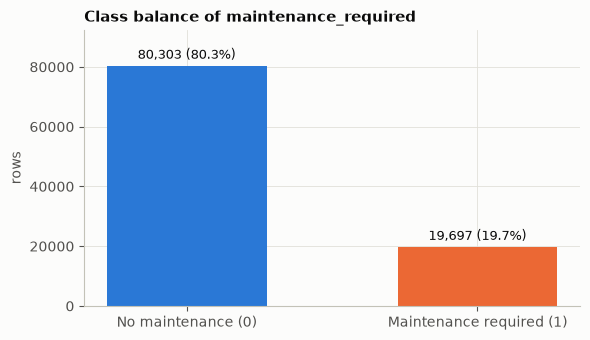

In [21]:
target_counts = df[TARGET].value_counts().sort_index()
target_share = target_counts / len(df) * 100
display(pd.DataFrame({"rows": target_counts, "share_%": target_share.round(2)}))
print(f"Imbalance ratio (0 : 1) = {target_counts[0] / target_counts[1]:.2f} : 1")
print(f"Accuracy of always predicting 'no maintenance' = {target_share[0]:.2f}%")

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar([TARGET_LABELS[k] for k in target_counts.index], target_counts.values,
              color=[TARGET_COLORS[k] for k in target_counts.index], width=0.55)
for bar, share in zip(bars, target_share.values):
    ax.annotate(f"{bar.get_height():,.0f} ({share:.1f}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=9, color=INK)
ax.set(title="Class balance of maintenance_required", ylabel="rows", ylim=(0, target_counts.max() * 1.15))
plt.tight_layout()
plt.show()

**Interpretation & conclusion.**

* **19,697 rows (19.70%) need maintenance and 80,303 (80.30%) do not** – an imbalance of about **4.08 : 1**.
* A model that always predicts "no maintenance" already scores **80.30% accuracy** while catching zero machines
  that need maintenance. **Accuracy is therefore misleading** for this problem.
* Implications for Task 2:
  * Use a **stratified** train/test split (and stratified cross-validation) so both sets keep the 19.7% positive rate.
  * Evaluate with **recall, precision, F1 and PR-AUC** for the positive class, plus the confusion matrix. Missing a
    machine that needs maintenance (false negative) causes unscheduled downtime, which the business wants to avoid,
    so **recall on class 1 is the priority**, balanced against precision so the maintenance team is not flooded
    with false alerts.
  * Consider `class_weight="balanced"` (or tuning the decision threshold) to counter the imbalance.

## 6. Univariate analysis

**Purpose.** Understand the shape (centre, spread, skew, range) of each feature on its own. This guides
scaling/transformation decisions and helps judge how realistic the data is.

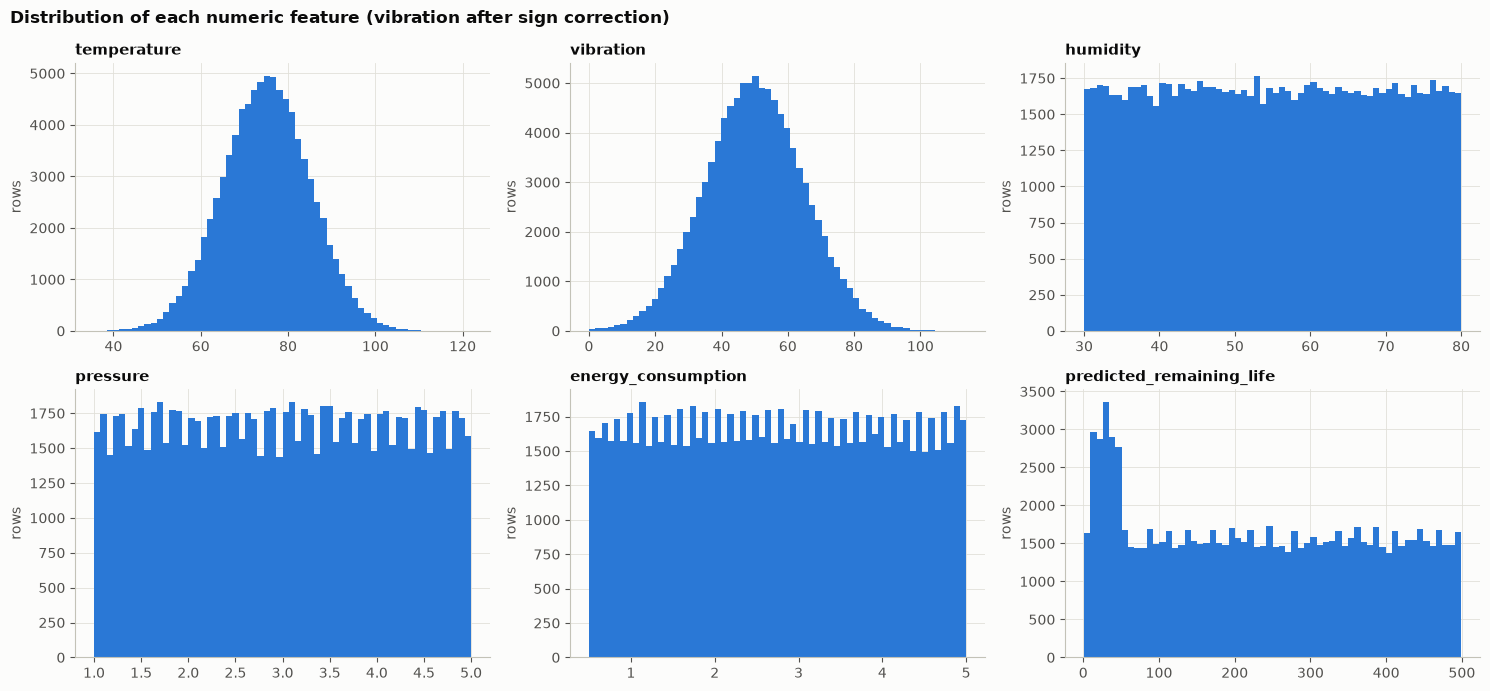

In [22]:
numeric_cols = SENSOR_COLS + ["predicted_remaining_life"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(df[col].dropna(), bins=60, color=BLUE)
    ax.set(title=col, ylabel="rows")
fig.suptitle("Distribution of each numeric feature (vibration after sign correction)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [23]:
shape_stats = pd.DataFrame({
    "mean": df[numeric_cols].mean(), "std": df[numeric_cols].std(),
    "min": df[numeric_cols].min(), "max": df[numeric_cols].max(),
    "skewness": df[numeric_cols].skew(), "excess_kurtosis": df[numeric_cols].kurt(),
})
# Kolmogorov-Smirnov distance to a uniform distribution over the observed range (0 = perfectly uniform).
shape_stats["KS_distance_to_uniform"] = [
    stats.kstest(df[c].dropna(), "uniform", args=(df[c].min(), df[c].max() - df[c].min())).statistic
    for c in numeric_cols
]
shape_stats.round(3)

,mean,std,min,max,skewness,excess_kurtosis,KS_distance_to_uniform
temperature,75.0340,10.0360,35.5500,121.9400,-0.0090,0.0150,0.3030
vibration,50.0160,14.9740,0.0200,113.8000,0.0140,-0.0240,0.2960
humidity,54.9950,14.4380,30.0000,80.0000,0.0010,-1.2000,0.0010
pressure,3.0000,1.1520,1.0000,5.0000,-0.0010,-1.1970,0.0030
energy_consumption,2.7470,1.2980,0.5000,5.0000,0.0070,-1.1950,0.0040
predicted_remaining_life,234.2690,150.0630,1.0000,499.0000,0.0870,-1.2710,0.0670


**Interpretation & conclusion.**

* **`temperature`** is bell-shaped around **75 °C (std ≈ 10)** with skewness ≈ 0 – close to a normal distribution.
* **`vibration`** (after sign correction) is bell-shaped around **50 mm/s (std ≈ 15)**.
* **`humidity` (30–80 %), `pressure` (1–5 bar) and `energy_consumption` (0.5–5 kWh)** are **flat (uniform)**: the
  KS distance to a uniform distribution is ≤ 0.004 and the excess kurtosis is ≈ -1.2, the value expected for a uniform
  distribution. Uniformly spread values that do not cluster around a typical operating point suggest these columns
  behave like random numbers rather than physical measurements – an early hint that they may carry little
  information (confirmed in Section 7).
* **`predicted_remaining_life` (1–499 h)** is flat from ~50 h upwards but has a **clear excess of readings below
  50 h**. Section 7.2 shows that this excess comes from the anomaly readings.
* Skewness is close to 0 for every feature (|skew| < 0.1), so **no log/power transformation is needed**. Ranges differ
  a lot (1–5 vs 1–499), so scale-sensitive models (logistic regression, SVM, KNN) need **standardisation**; tree
  models do not.

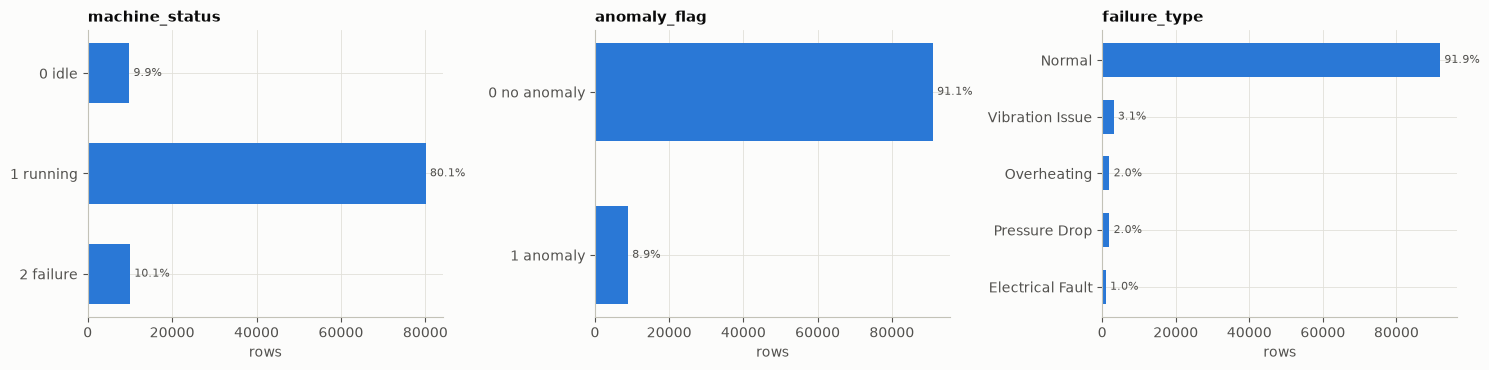

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
status_names = {0: "0 idle", 1: "1 running", 2: "2 failure"}
for ax, col, labels in [(axes[0], "machine_status", status_names),
                        (axes[1], "anomaly_flag", {0: "0 no anomaly", 1: "1 anomaly"}),
                        (axes[2], "failure_type", None)]:
    counts = df[col].value_counts().sort_index() if labels else df[col].value_counts()
    names = [labels[i] for i in counts.index] if labels else counts.index
    ax.barh(names, counts.values, color=BLUE, height=0.6)
    for y_pos, value in enumerate(counts.values):
        ax.annotate(f"{value / len(df):.1%}", (value, y_pos), xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK_2)
    ax.set(title=col, xlabel="rows")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation & conclusion.**

* `machine_status`: **80.1% running, 9.9% idle, 10.1% failure.**
* `anomaly_flag`: **8.9% of readings are anomalies.**
* `failure_type`: **91.9% `Normal`**; among real failure labels, *Vibration Issue* is the most common (3.1%) and
  *Electrical Fault* the least (1.0%). The categories are highly imbalanced, so `failure_type` would be a poor
  multi-class target as well as a leaky feature (Section 4.5).

## 7. Bivariate analysis – features vs `maintenance_required`

### 7.1 Sensor readings vs target

**Purpose.** Measure which sensors differ between readings that need maintenance and those that do not.
We use the **Mann–Whitney U test** (does not assume normality) and the **rank-biserial correlation r** as effect
size. With 100,000 rows even tiny differences become "significant", so the **effect size** is what tells us
whether a difference is large enough to matter: |r| ≈ 0.1 small, ≈ 0.3 medium, ≥ 0.5 large.

In [25]:
rows = []
for col in SENSOR_COLS:
    pos = df.loc[df[TARGET] == 1, col].dropna()
    neg = df.loc[df[TARGET] == 0, col].dropna()
    p_value, r = rank_biserial(pos, neg)
    rows.append({"feature": col, "median_no_maint": neg.median(), "median_maint": pos.median(),
                 "mann_whitney_p": p_value, "rank_biserial_r": r})
sensor_tests = pd.DataFrame(rows).sort_values("rank_biserial_r", key=abs, ascending=False)
sensor_tests.round(4)

,feature,median_no_maint,median_maint,mann_whitney_p,rank_biserial_r
0,temperature,74.2300,80.6550,0.0000,0.3431
1,vibration,49.5300,51.9000,0.0000,0.1173
2,humidity,55.0100,54.8500,0.2272,-0.0055
3,pressure,3.0100,2.9900,0.5390,-0.0028
4,energy_consumption,2.7400,2.7500,0.6627,0.0020


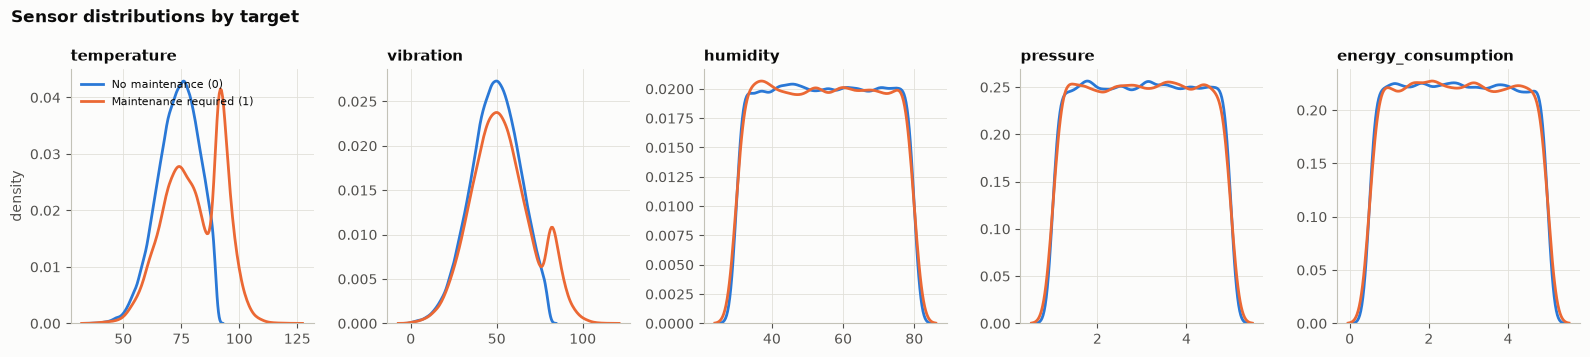

In [26]:
fig, axes = plt.subplots(1, len(SENSOR_COLS), figsize=(16, 3.6))
for ax, col in zip(axes, SENSOR_COLS):
    for value in (0, 1):
        sns.kdeplot(df.loc[df[TARGET] == value, col].dropna(), ax=ax, color=TARGET_COLORS[value],
                    linewidth=2, common_norm=False, label=TARGET_LABELS[value])
    ax.set(title=col, xlabel="", ylabel="")
axes[0].set_ylabel("density")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Sensor distributions by target", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

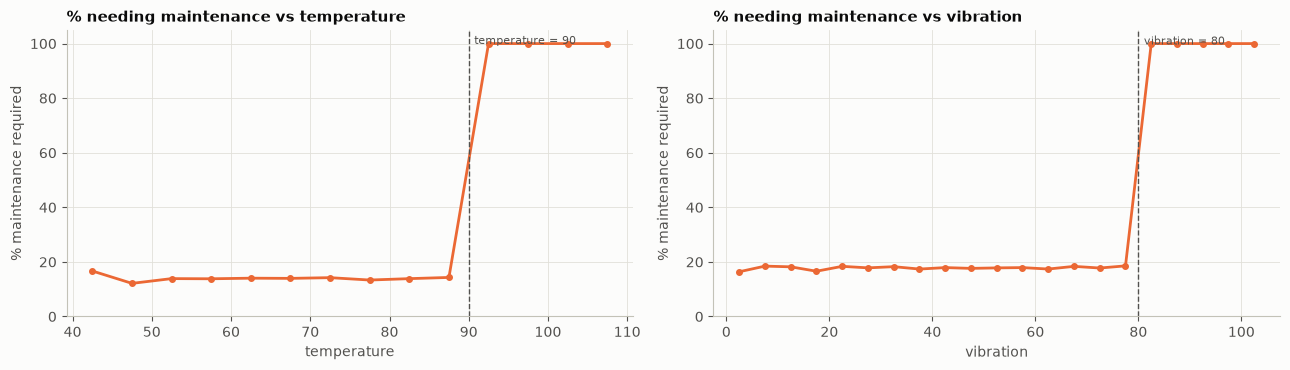

In [27]:
# Maintenance rate as a function of the two informative sensors (5-unit bins).
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, threshold in [(axes[0], "temperature", 90), (axes[1], "vibration", 80)]:
    bins = np.arange(np.floor(df[col].min() / 5) * 5, df[col].max() + 5, 5)
    rate = maintenance_rate(df, pd.cut(df[col], bins))
    rate = rate[rate["rows"] >= 30]  # hide sparse bins
    ax.plot([b.mid for b in rate.index], rate["maintenance_rate"], color=ORANGE, linewidth=2, marker="o", markersize=4)
    add_reference_line(ax, threshold, f"{col} = {threshold}", axis="x")
    ax.set(title=f"% needing maintenance vs {col}", xlabel=col, ylabel="% maintenance required", ylim=(0, 105))
plt.tight_layout()
plt.show()

**Interpretation & conclusion.**

* **`temperature` is the strongest sensor** (median 74.2 °C vs 80.7 °C, r ≈ 0.34 – a medium effect). The rate
  plot shows a **sharp step at 90 °C**: above 90 °C *every* reading needs maintenance, below it the rate stays
  at ~12–17%.
* **`vibration` is the second sensor** (small effect overall, r ≈ 0.12), but the rate plot shows a **step at
  80 mm/s**: above it every reading needs maintenance, below it the rate stays at ~16–19%. The overall effect is
  small because only ~2% of readings exceed 80 mm/s.
* The KDE plots show the same thing: the orange (maintenance) curves have an **extra bump just above 90 °C and
  80 mm/s**, where the blue curves stop.
* **`humidity`, `pressure` and `energy_consumption` show no meaningful difference** (|r| < 0.01; the two class
  distributions overlap almost perfectly). They are unlikely to help the model.
* The step shapes mean the relationship is **non-linear (threshold-based)**. Tree-based models (Decision Tree,
  Random Forest, Gradient Boosting) capture thresholds naturally; a linear model would need explicit threshold
  features (Section 13).

### 7.2 Derived columns vs target

**Purpose.** Check how each derived column relates to the target. Strong relationships here may mean the column
is part of how the target was created (leakage), which is examined in Section 9.

In [28]:
for col in ["machine_status", "anomaly_flag", "failure_type"]:
    display(maintenance_rate(df, col))

,rows,maintenance_rate
machine_status,,
0,9852,10.9200
1,80091,10.6900
2,10057,100.0000


,rows,maintenance_rate
anomaly_flag,,
0,91084,11.8400
1,8916,100.0000


,rows,maintenance_rate
failure_type,,
Electrical Fault,1014,100.0000
Normal,91899,12.6200
Overheating,1989,100.0000
Pressure Drop,1969,100.0000
Vibration Issue,3129,100.0000


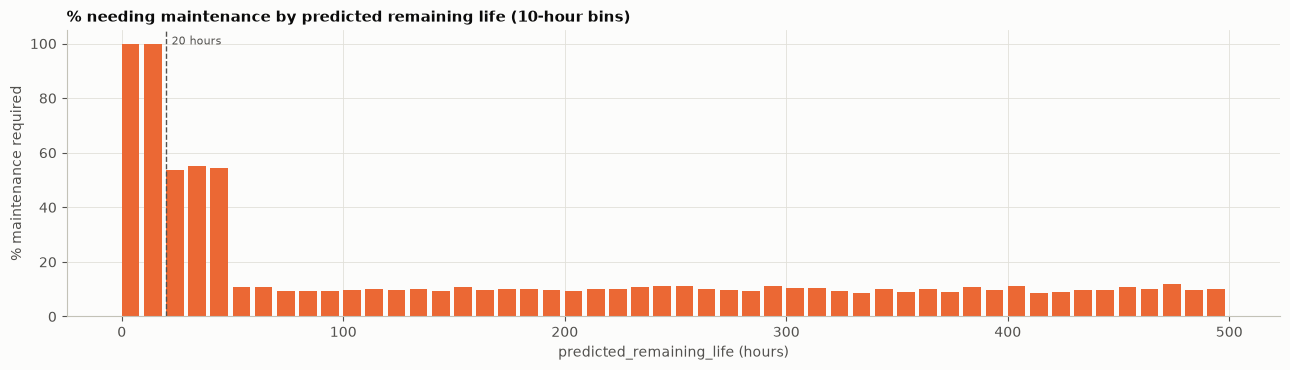

Smallest predicted_remaining_life among NON-maintenance rows: 20 hours


,rows,maintenance_rate
predicted_remaining_life,,
"[0, 10)",1637,100.0000
"[10, 20)",3695,100.0000
"[20, 30)",3645,53.7400
"[30, 40)",3715,55.2400
"[40, 50)",3641,54.5200
"[50, 60)",1863,10.6300


predicted_remaining_life by anomaly_flag:


,count,mean,std,min,25%,50%,75%,max
anomaly_flag,,,,,,,,
0,"91,084.0000",254.7554,141.4093,10.0000,133.0000,254.0000,377.0000,499.0000
1,"8,916.0000",24.9860,14.1167,1.0000,13.0000,25.0000,37.0000,49.0000


In [29]:
# right=False gives bins [0,10), [10,20), ... so the "< 20 hours" bins line up exactly with the 20-hour mark.
rul_rate = maintenance_rate(df, pd.cut(df["predicted_remaining_life"], np.arange(0, 510, 10), right=False))
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar([b.left for b in rul_rate.index], rul_rate["maintenance_rate"], width=8, align="edge", color=ORANGE)
add_reference_line(ax, 20, "20 hours", axis="x")
ax.set(title="% needing maintenance by predicted remaining life (10-hour bins)",
       xlabel="predicted_remaining_life (hours)", ylabel="% maintenance required", ylim=(0, 105))
plt.tight_layout()
plt.show()
print(f"Smallest predicted_remaining_life among NON-maintenance rows: "
      f"{df.loc[df[TARGET] == 0, 'predicted_remaining_life'].min()} hours")
display(rul_rate.head(6))
print("predicted_remaining_life by anomaly_flag:")
display(df.groupby("anomaly_flag")["predicted_remaining_life"].describe())

**Interpretation & conclusion.**

* **`machine_status = 2` (failure) → 100% maintenance**; idle (10.9%) and running (10.7%) machines have the same
  lower rate, so idle vs running does not matter.
* **`anomaly_flag = 1` → 100% maintenance** (and `failure_type` ≠ Normal → 100% maintenance).
* **`predicted_remaining_life` < 20 hours → 100% maintenance**: no non-maintenance row has a remaining life below
  20 hours. Between 20 and 49 hours the rate is ~54–55%, and from 50 hours upwards it is flat at ~9–12%.
* The reason for the 20–49 h band: **every anomaly has a predicted remaining life between 1 and 49 hours**, while
  non-anomaly readings range from 10 to 499 hours. So `predicted_remaining_life` is itself partly derived from
  `anomaly_flag`, which also explains the excess of short remaining lives seen in Section 6.
* Three derived columns each give a **perfect "if X then maintenance" rule**. This is far too clean to be
  coincidence and is investigated as possible **target leakage** in Section 9.

## 8. Multivariate analysis

### 8.1 Correlation matrix

**Purpose.** Identify redundant features (high correlation with each other) and features related to the target.
**Spearman** rank correlation is used because it captures any monotonic relationship, not just straight lines,
and is robust to outliers.

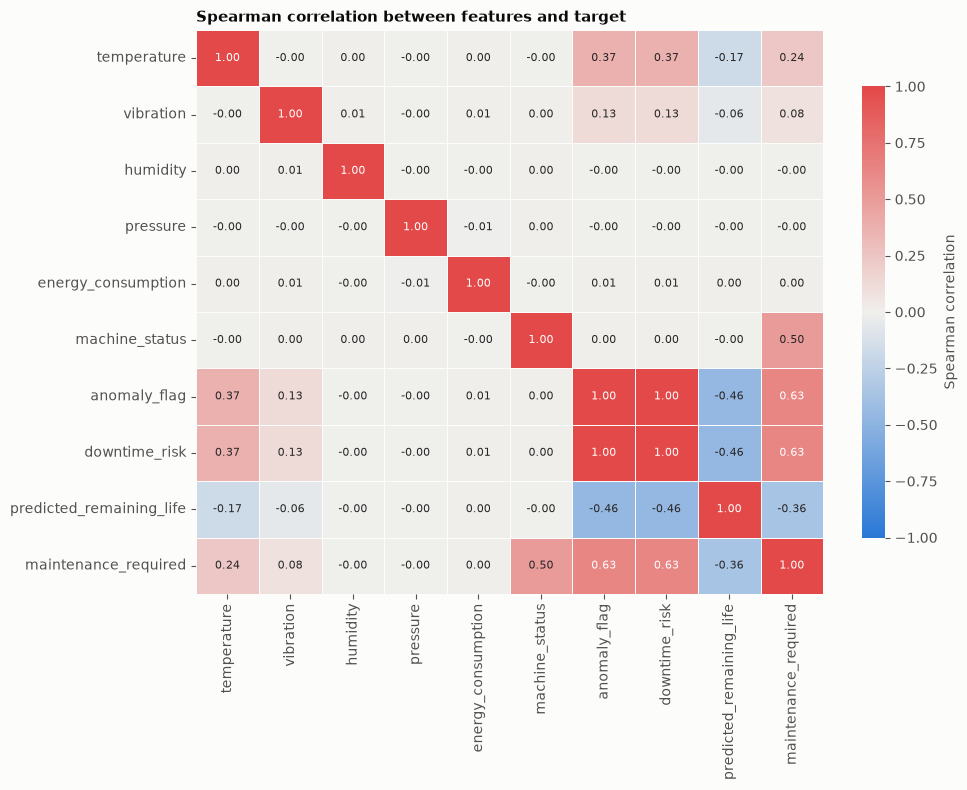

Spearman correlation with the target, strongest first:


,maintenance_required
anomaly_flag,0.6320
downtime_risk,0.6320
machine_status,0.5040
predicted_remaining_life,-0.3650
temperature,0.2370
vibration,0.0810
humidity,-0.0040
pressure,-0.0020
energy_consumption,0.0010


In [30]:
corr_cols = SENSOR_COLS + ["machine_status", "anomaly_flag", "downtime_risk", "predicted_remaining_life", TARGET]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor=SURFACE, annot_kws={"fontsize": 8},
            cbar_kws={"label": "Spearman correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation between features and target")
plt.tight_layout()
plt.show()
print("Spearman correlation with the target, strongest first:")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame())

**Interpretation & conclusion.**

* **The sensors are uncorrelated with each other** (all |ρ| ≤ 0.01). Each sensor carries independent information,
  so there is no multicollinearity to remove. It also means **other sensors cannot help predict a missing
  temperature** – important for the imputation choice in Section 12.
* **`anomaly_flag` and `downtime_risk` are perfectly correlated (ρ = 1.00)** → confirms `downtime_risk` is redundant.
* Correlations with the target: `anomaly_flag` and `downtime_risk` (0.63), `machine_status` (0.50, because of the
  failure state), `predicted_remaining_life` (-0.37), `temperature` (0.24), `vibration` (0.08). Humidity, pressure
  and energy ≈ 0.
* `predicted_remaining_life` is negatively correlated with `anomaly_flag` (ρ = -0.46), matching the finding that
  anomalies always have a remaining life below 50 hours (Section 7.2).
* `temperature` is weakly related to `predicted_remaining_life` (ρ ≈ -0.17): hotter readings get a shorter predicted
  life, mostly through the readings above 90 °C. This is the main route by which sensors can explain the
  low-remaining-life cases.

### 8.2 Joint behaviour of temperature and vibration

**Purpose.** Section 7 found threshold steps at 90 °C and 80 mm/s. Plotting both sensors together shows how the
anomaly flag is formed from them.

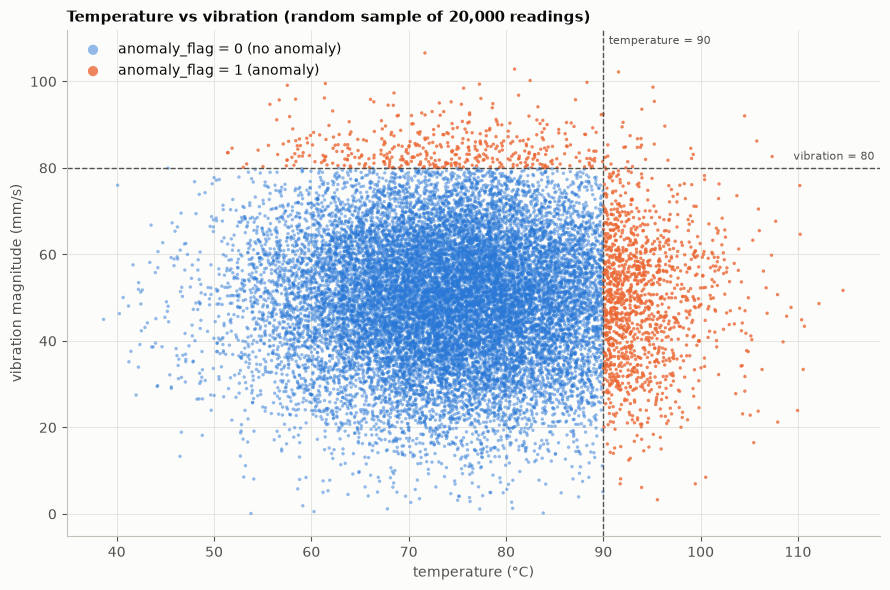

In [31]:
sample = df.dropna(subset=["temperature"]).sample(20_000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 6))
for flag, label in [(0, "no anomaly"), (1, "anomaly")]:
    part = sample[sample["anomaly_flag"] == flag]
    ax.scatter(part["temperature"], part["vibration"], s=6, alpha=0.5 if flag == 0 else 0.8,
               color=TARGET_COLORS[flag], label=f"anomaly_flag = {flag} ({label})", edgecolors="none")
add_reference_line(ax, 90, "temperature = 90", axis="x")
add_reference_line(ax, 80, "vibration = 80")
ax.set(title="Temperature vs vibration (random sample of 20,000 readings)",
       xlabel="temperature (°C)", ylabel="vibration magnitude (mm/s)")
ax.legend(loc="upper left", markerscale=3)
plt.tight_layout()
plt.show()

**Interpretation & conclusion.** The anomalies (orange) fill exactly the region **temperature > 90 °C OR
vibration > 80 mm/s**, and the box below and to the left of the dashed lines contains only normal (blue) readings.
The two sensors act independently: a reading is an anomaly if *either* one crosses its threshold. The anomaly flag
is therefore a **simple threshold rule on two sensors**, verified exactly in Section 9.3.

## 9. Derived columns & target leakage

**Purpose.** The Problem Statement notes that "some columns are derived data". If the target is computed from
other columns, a model given those columns can simply re-learn the formula: it will score near-perfectly in
testing but has learned nothing useful for *predicting maintenance in advance*. This is called **target leakage**
and is the most important thing to settle before building the pipeline.

### 9.1 Can the derived columns reproduce the target?

A shallow decision tree is used here only as an **analysis tool** to discover rules, not as a final model.

In [32]:
leak_features = ["anomaly_flag", "machine_status", "predicted_remaining_life"]
rule_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
rule_tree.fit(df[leak_features], df[TARGET])
print(export_text(rule_tree, feature_names=leak_features, show_weights=True))
print(f"Training accuracy of a depth-3 tree on 3 derived columns: {rule_tree.score(df[leak_features], df[TARGET]):.4%}")

|--- machine_status <= 1.50
|   |--- anomaly_flag <= 0.50
|   |   |--- predicted_remaining_life <= 19.50
|   |   |   |--- weights: [0.00, 1648.00] class: 1
|   |   |--- predicted_remaining_life >  19.50
|   |   |   |--- weights: [80303.00, 0.00] class: 0
|   |--- anomaly_flag >  0.50
|   |   |--- weights: [0.00, 7992.00] class: 1
|--- machine_status >  1.50
|   |--- weights: [0.00, 10057.00] class: 1

Training accuracy of a depth-3 tree on 3 derived columns: 100.0000%


In [33]:
# Write the discovered rule out explicitly and check it on every row.
rule = (df["anomaly_flag"] == 1) | (df["machine_status"] == 2) | (df["predicted_remaining_life"] < 20)
print("Rule: anomaly_flag == 1  OR  machine_status == 2  OR  predicted_remaining_life < 20")
display(pd.crosstab(rule.rename("rule_says_maintenance"), df[TARGET]))
print(f"Rows where the rule disagrees with the target: {(rule.astype(int) != df[TARGET]).sum()}")

Rule: anomaly_flag == 1  OR  machine_status == 2  OR  predicted_remaining_life < 20


maintenance_required,0,1
rule_says_maintenance,,
False,80303,0
True,0,19697


Rows where the rule disagrees with the target: 0


**Interpretation.** The target is **exactly** reproduced, on all 100,000 rows with **zero exceptions**, by:

> `maintenance_required = 1`  ⇔  `anomaly_flag = 1`  **OR**  `machine_status = 2`  **OR**  `predicted_remaining_life < 20`

So `maintenance_required` is itself a derived column built from three other derived columns.

### 9.2 Which condition triggers each maintenance case?

**Purpose.** Find out how much of the target each condition is responsible for, and therefore what a model
that *cannot* see the derived columns could at best hope to detect.

,rows,share_of_positives_%
failure status,8929,45.3300
anomaly,4861,24.6800
anomaly + RUL < 20 h,3131,15.9000
RUL < 20 h,1648,8.3700
anomaly + failure status,575,2.9200
anomaly + failure status + RUL < 20 h,349,1.7700
failure status + RUL < 20 h,204,1.0400


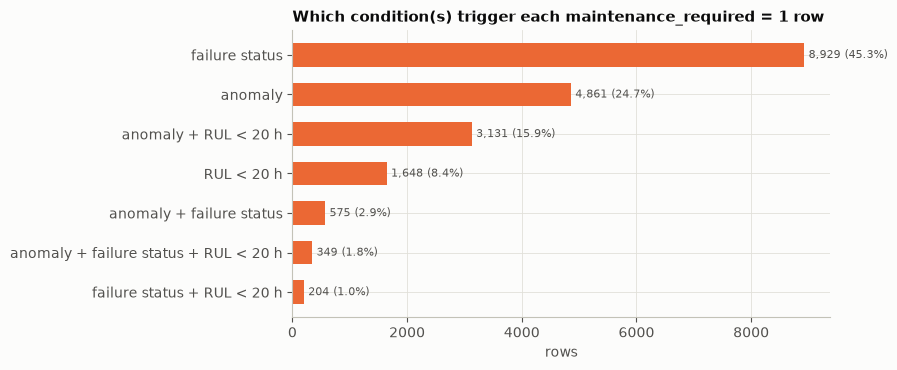

Average sensor readings by machine_status:


,temperature,vibration,humidity,pressure,energy_consumption
machine_status,,,,,
0,75.1300,49.7700,54.8800,3.0000,2.7600
1,75.0100,50.0500,55.0100,3.0000,2.7500
2,75.0900,49.9700,54.9800,3.0000,2.7400


In [34]:
positives = df[df[TARGET] == 1]
conditions = pd.DataFrame({
    "anomaly": positives["anomaly_flag"] == 1,
    "failure status": positives["machine_status"] == 2,
    "RUL < 20 h": positives["predicted_remaining_life"] < 20,
})
combo = conditions.apply(lambda r: " + ".join(c for c in conditions.columns if r[c]), axis=1)
combo_counts = combo.value_counts()
display(pd.DataFrame({"rows": combo_counts, "share_of_positives_%": (combo_counts / len(positives) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(combo_counts.index, combo_counts.values, color=ORANGE, height=0.6)
for y_pos, value in enumerate(combo_counts.values):
    ax.annotate(f"{value:,} ({value / len(positives):.1%})", (value, y_pos), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK_2)
ax.invert_yaxis()
ax.set(title="Which condition(s) trigger each maintenance_required = 1 row", xlabel="rows")
plt.tight_layout()
plt.show()

print("Average sensor readings by machine_status:")
display(df.groupby("machine_status")[SENSOR_COLS].mean().round(2))

**Interpretation.** Every positive is triggered by at least one condition. The largest single group is
**failure status only** (8,929 rows, ~45% of positives). The table above shows that the failure state
(`machine_status = 2`) has **the same average sensor readings as idle and running machines**, and Section 8.1 shows
`machine_status` is uncorrelated with every sensor. Those cases therefore cannot be predicted from sensor readings
alone.

### 9.3 How is `anomaly_flag` produced?

In [35]:
observed = df.dropna(subset=["temperature"])
anomaly_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
anomaly_tree.fit(observed[["temperature", "vibration"]], observed["anomaly_flag"])
print(export_text(anomaly_tree, feature_names=["temperature", "vibration"], show_weights=True))

sensor_rule = (df["temperature"] > 90) | (df["vibration"] > 80)
print("Rule: temperature > 90  OR  |vibration| > 80")
display(pd.crosstab([sensor_rule.rename("sensor_rule"), df["temperature"].isna().rename("temperature_missing")],
                    df["anomaly_flag"]))
mismatch = (~sensor_rule) & df["temperature"].notna() & (df["anomaly_flag"] == 1)
print("Anomalies with known temperature that the rule misses:")
display(df.loc[mismatch, ["temperature", "vibration", "anomaly_flag"]])

|--- temperature <= 90.01
|   |--- vibration <= 79.99
|   |   |--- weights: [78310.00, 3.00] class: 0
|   |--- vibration >  79.99
|   |   |--- weights: [2.00, 1853.00] class: 1
|--- temperature >  90.01
|   |--- weights: [0.00, 5832.00] class: 1

Rule: temperature > 90  OR  |vibration| > 80


anomaly_flag                         0     1
sensor_rule temperature_missing             
False       False                78312     5
            True                 12772   922
True        False                    0  7683
            True                     0   306

Anomalies with known temperature that the rule misses:


,temperature,vibration,anomaly_flag
8005,73.0500,80.0000,1
27676,90.0000,46.3100,1
32761,90.0000,53.4400,1
72925,70.7300,80.0000,1
79388,90.0000,62.6400,1


**Interpretation & conclusion.**

* **`anomaly_flag = 1` ⇔ temperature > 90 °C OR |vibration| > 80 mm/s.** When temperature is known, the rule
  disagrees with the label on only 5 of 86,000 rows, and all 5 sit **exactly on the boundary** (temperature = 90.00 or
  vibration = 80.00), i.e. the true reading was slightly above the threshold and was rounded to 2 decimals.
* **922 anomalies have a missing temperature and vibration ≤ 80.** For these, the only possible trigger is a
  temperature above 90 °C that was not recorded. **This matters for imputation:** filling these gaps with a typical
  value (~75 °C) hides the very reading that caused the anomaly (Section 12.2).

### 9.4 Leakage summary and decision for Task 2

| Column | Role in the target | Available *before* maintenance is needed? | Recommendation |
|--------|--------------------|-------------------------------------------|----------------|
| `anomaly_flag` | Directly part of the target rule | It is a threshold on temperature and vibration | **Exclude** – recreate it from the sensors instead (Section 13) |
| `downtime_risk` | Copy of `anomaly_flag` | Same as above | **Exclude** (redundant) |
| `machine_status` | `= 2` directly part of the target rule | Status 2 *is* the failure the alert should prevent | **Exclude** from the main feature set |
| `failure_type` | Only non-Normal when status = 2 | Known only after the failure | **Exclude** |
| `predicted_remaining_life` | `< 20` directly part of the target rule | Output of another (prognostic) model | **Exclude** from the main feature set; optional experiment |

**Decision.** If these columns are given to a model, any tree model will reach ~100% test scores by re-learning the
rule above, which would be **meaningless for an early-warning system**. The pipeline should therefore be
**configurable** with two feature sets:

1. **`sensor` feature set (main, recommended):** sensors and features engineered from them only.
   This answers the business question *"can we tell from the sensor readings that a machine needs maintenance?"*
2. **`all` feature set (comparison only):** includes the derived columns, to demonstrate the leakage and why it
   was rejected.

Because ~45% of the positives come only from the failure state, which no sensor reflects, **sensor-only models
will have a realistic recall ceiling well below 100%**. This is a property of the data, not a modelling mistake,
and should be explained in the README and presentation.

## 10. Temporal & machine-level patterns

**Purpose.** If maintenance depends on the time of day, day of week, date or the particular machine, those should
become features – and strong time dependence would also require a time-based (not random) train/test split.

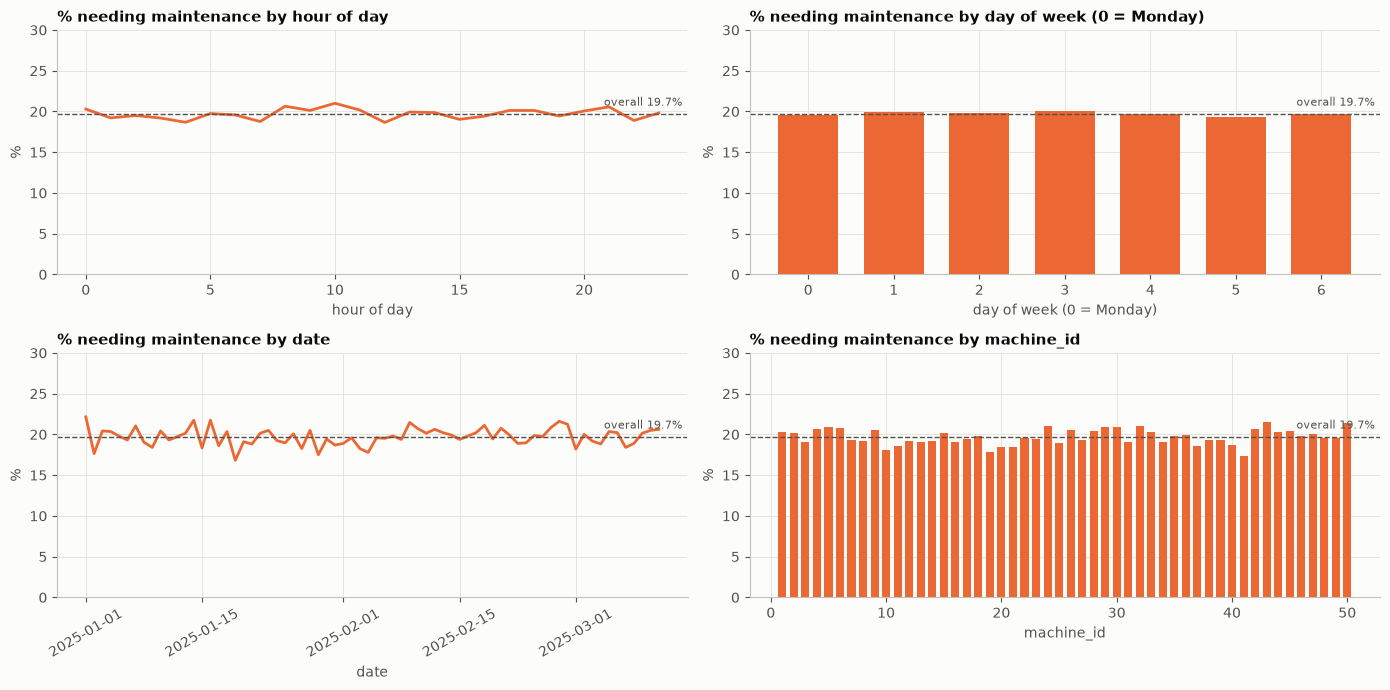

In [36]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.day_of_week          # 0 = Monday
df["date"] = df["timestamp"].dt.date

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
overall = df[TARGET].mean() * 100
panels = [(axes[0, 0], "hour", "hour of day"), (axes[0, 1], "day_of_week", "day of week (0 = Monday)"),
          (axes[1, 0], "date", "date"), (axes[1, 1], "machine_id", "machine_id")]
for ax, col, xlabel in panels:
    rate = maintenance_rate(df, col)["maintenance_rate"]
    if col in ("hour", "date"):
        ax.plot(rate.index, rate.values, color=ORANGE, linewidth=2)
    else:
        ax.bar(rate.index, rate.values, color=ORANGE, width=0.7)
    add_reference_line(ax, overall, f"overall {overall:.1f}%")
    ax.set(title=f"% needing maintenance by {xlabel}", xlabel=xlabel, ylabel="%", ylim=(0, 30))
axes[1, 0].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [37]:
time_tests = []
for col in ["hour", "day_of_week", "machine_id"]:
    chi2, p, dof = chi_square(df[col], df[TARGET])
    time_tests.append({"feature": col, "chi2": chi2, "dof": dof, "p_value": p})
display(pd.DataFrame(time_tests).round(4))

# Lag-1 autocorrelation within each machine: does a machine's previous reading predict its next one?
ordered = df.sort_values(["machine_id", "timestamp"])
lag_rows = []
for col in [TARGET, "temperature", "vibration", "predicted_remaining_life", "anomaly_flag"]:
    previous = ordered.groupby("machine_id")[col].shift(1)
    lag_rows.append({"column": col, "lag1_autocorrelation": ordered[col].corr(previous)})
pd.DataFrame(lag_rows).round(4)

,feature,chi2,dof,p_value
0,hour,25.0021,23,0.3502
1,day_of_week,3.6917,6,0.7183
2,machine_id,55.6600,49,0.2385


,column,lag1_autocorrelation
0,maintenance_required,0.0068
1,temperature,-0.0020
2,vibration,0.0020
3,predicted_remaining_life,0.0029
4,anomaly_flag,0.0024


**Interpretation & conclusion.**

* The maintenance rate is **flat across hours, days of the week, dates and machines**; all lines/bars stay close to
  the overall 19.7%. The chi-square tests confirm **no significant dependence** on hour, day of week or machine
  (all p > 0.05).
* **Lag-1 autocorrelation is ≈ 0** for the target and every sensor: a machine's previous reading says nothing about
  its next one. `predicted_remaining_life` does not count down over time either. Each reading behaves like an
  **independent observation**.
* Decisions for Task 2:
  * **Do not engineer time features** (hour, weekday, rolling averages, lags) – there is no temporal signal to
    capture, and they would only add noise.
  * **Drop `machine_id`** as a feature – no machine is more maintenance-prone than another, and one-hot encoding 50
    machines would add 50 noise columns.
  * A **stratified random train/test split is appropriate**, because there is no time dependence or drift that a
    random split could leak across.

In [38]:
df = df.drop(columns=["hour", "day_of_week", "date"])  # analysis-only columns

## 11. Feature relevance – mutual information

**Purpose.** Rank all candidate features by how much information they share with the target. **Mutual information
(MI)** captures any kind of relationship, including the threshold effects found above, which correlation can
underestimate. MI = 0 means the feature tells us nothing about the target. Rows with missing temperature are
excluded here so that imputation does not influence the ranking.

,feature,mutual_information,group
0,machine_status,0.1899,derived (leakage risk)
1,downtime_risk,0.1653,derived (leakage risk)
2,anomaly_flag,0.1651,derived (leakage risk)
3,predicted_remaining_life,0.1497,derived (leakage risk)
4,failure_type,0.1483,derived (leakage risk)
5,temperature,0.1202,sensor / identifier
6,vibration,0.0396,sensor / identifier
7,machine_id,0.0003,sensor / identifier
8,humidity,0.0000,sensor / identifier
9,pressure,0.0000,sensor / identifier


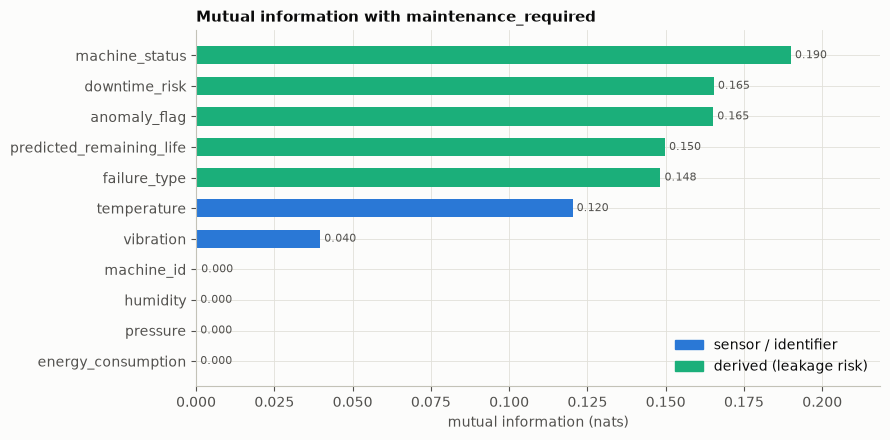

In [39]:
mi_data = df.dropna(subset=["temperature"]).copy()
mi_data["failure_type"] = mi_data["failure_type"].astype("category").cat.codes
mi_features = {  # feature -> is it discrete?
    "temperature": False, "vibration": False, "humidity": False, "pressure": False,
    "energy_consumption": False, "machine_id": True,
    "machine_status": True, "anomaly_flag": True, "downtime_risk": False,
    "predicted_remaining_life": False, "failure_type": True,
}
mi = mutual_info_classif(mi_data[list(mi_features)], mi_data[TARGET],
                         discrete_features=list(mi_features.values()), random_state=RANDOM_STATE)
mi_scores = pd.DataFrame({"feature": list(mi_features), "mutual_information": mi})
mi_scores["group"] = np.where(mi_scores["feature"].isin(DERIVED_COLS), "derived (leakage risk)", "sensor / identifier")
mi_scores = mi_scores.sort_values("mutual_information", ascending=False).reset_index(drop=True)
display(mi_scores.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
group_colors = {"sensor / identifier": BLUE, "derived (leakage risk)": AQUA}
ax.barh(mi_scores["feature"], mi_scores["mutual_information"],
        color=mi_scores["group"].map(group_colors), height=0.6)
for y_pos, value in enumerate(mi_scores["mutual_information"]):
    ax.annotate(f"{value:.3f}", (value, y_pos), xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)
ax.invert_yaxis()
ax.set_xlim(0, mi_scores["mutual_information"].max() * 1.15)
ax.legend(handles=[Patch(color=color, label=name) for name, color in group_colors.items()], loc="lower right")
ax.set(title="Mutual information with maintenance_required", xlabel="mutual information (nats)")
plt.tight_layout()
plt.show()

**Interpretation & conclusion.**

* The **derived columns take the top five places** (`machine_status`, `downtime_risk`, `anomaly_flag`,
  `predicted_remaining_life`, `failure_type`), as expected from the leakage analysis.
* Among the legitimate sensor features, **`temperature` is clearly the most informative, followed by `vibration`**.
* **`humidity`, `pressure`, `energy_consumption` and `machine_id` have MI ≈ 0** – consistent with the
  Mann–Whitney, correlation and chi-square results. They can be kept in the pipeline for completeness (and to let
  the models confirm their low importance), but they are not expected to improve performance.

## 12. Imputation of missing temperature

### 12.1 Comparing imputation techniques

**Purpose.** Choose the imputation technique on evidence instead of habit. We **hide 10% of the known
temperatures**, fill them in with each technique, and measure how close the filled values are to the true ones
(RMSE and MAE, in °C – lower is better).

Techniques compared:
* **Mean / Median** – replace with one overall value.
* **Per-machine median** – replace with that machine's median (useful if machines run at different temperatures).
* **KNN imputer** – average temperature of the 5 most similar readings, based on the other sensors.
* **Iterative imputer** – regression of temperature on the other sensors *and* `predicted_remaining_life`.

,RMSE_degC,MAE_degC
Iterative (sensors + RUL),9.8330,7.9370
mean,10.0360,8.0130
median,10.0360,8.0130
per-machine median,10.0400,8.0110
KNN (sensors),10.8880,8.6850


Standard deviation of temperature (error of a 'no-information' guess): 10.037 °C


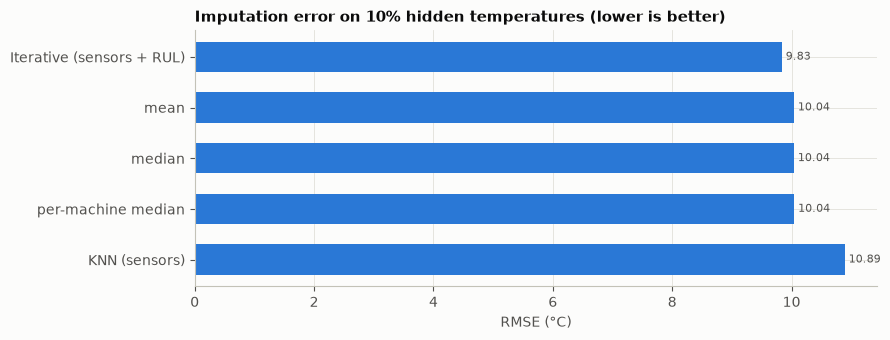

In [40]:
rng = np.random.default_rng(RANDOM_STATE)
known = df.dropna(subset=["temperature"]).copy()
hidden_idx = rng.choice(known.index, size=int(0.10 * len(known)), replace=False)
truth = known.loc[hidden_idx, "temperature"]
masked = known.copy()
masked.loc[hidden_idx, "temperature"] = np.nan
impute_cols = SENSOR_COLS  # temperature + the other sensors

estimates = {
    "mean": pd.Series(masked["temperature"].mean(), index=hidden_idx),
    "median": pd.Series(masked["temperature"].median(), index=hidden_idx),
    "per-machine median": masked.groupby("machine_id")["temperature"].transform("median").loc[hidden_idx],
}
# KNN is slow on 86k rows, so it is fitted on a 20k-row random sample (large enough for 5 neighbours).
knn = KNNImputer(n_neighbors=5).fit(masked[impute_cols].sample(20_000, random_state=RANDOM_STATE))
estimates["KNN (sensors)"] = pd.Series(knn.transform(masked.loc[hidden_idx, impute_cols])[:, 0], index=hidden_idx)
iter_cols = impute_cols + ["predicted_remaining_life"]
iterative = IterativeImputer(random_state=RANDOM_STATE).fit(masked[iter_cols])
estimates["Iterative (sensors + RUL)"] = pd.Series(
    iterative.transform(masked.loc[hidden_idx, iter_cols])[:, 0], index=hidden_idx)

imputation_scores = pd.DataFrame({
    "RMSE_degC": {name: np.sqrt(((est - truth) ** 2).mean()) for name, est in estimates.items()},
    "MAE_degC": {name: (est - truth).abs().mean() for name, est in estimates.items()},
}).sort_values("RMSE_degC")
display(imputation_scores.round(3))
print(f"Standard deviation of temperature (error of a 'no-information' guess): {truth.std():.3f} °C")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(imputation_scores.index, imputation_scores["RMSE_degC"], color=BLUE, height=0.6)
for y_pos, value in enumerate(imputation_scores["RMSE_degC"]):
    ax.annotate(f"{value:.2f}", (value, y_pos), xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)
ax.invert_yaxis()
ax.set(title="Imputation error on 10% hidden temperatures (lower is better)", xlabel="RMSE (°C)")
plt.tight_layout()
plt.show()

**Interpretation.**

* **Mean, median and per-machine median are equally accurate (RMSE ≈ 10.0 °C)**, which equals the standard
  deviation of temperature: they are the best "typical value" guess possible.
* **KNN is the worst (RMSE ≈ 10.9 °C).** Because temperature is uncorrelated with the other sensors (Section 8.1),
  the "nearest neighbours" are effectively random readings, and averaging five random temperatures adds noise.
* **The iterative imputer is only ~2% better (RMSE ≈ 9.8 °C)**, and only because it uses
  `predicted_remaining_life` – a derived column that the main (sensor) feature set excludes. The gain does not
  justify the extra complexity or the dependence on a leaky column.
* Per-machine median gives no gain because all machines have the same temperature profile.

### 12.2 Caveat – missing values that hide high temperatures

In [41]:
hidden_hot = df["temperature"].isna() & (df["anomaly_flag"] == 1) & (df["vibration"] <= 80)
median_temp = df["temperature"].median()
print(f"Rows whose missing temperature must have been > 90 °C (anomaly not explained by vibration): {hidden_hot.sum():,}")
print(f"Share of all missing-temperature rows: {hidden_hot.sum() / df['temperature'].isna().sum():.2%}")
print(f"Value the median imputer would give them: {median_temp:.2f} °C")

Rows whose missing temperature must have been > 90 °C (anomaly not explained by vibration): 922
Share of all missing-temperature rows: 6.59%
Value the median imputer would give them: 75.09 °C


**Interpretation.** About **6.6% of the missing temperatures hid a reading above 90 °C**. No imputer can recover them
from the other sensors, because temperature is independent of the other sensors. Imputed with the median, these
rows look normal, so a sensor-only model will miss them – another small, unavoidable limit on recall. Adding a
**`temperature_missing` indicator** at least lets the model know the reading is unknown rather than truly ~75 °C.

### 12.3 Decision and application

**Chosen technique: median imputation + a `temperature_missing` indicator column.**
* Median is as accurate as any alternative here, is robust to outliers, and is simple and fast.
* The indicator keeps the information that the value was imputed.
* **In the pipeline, the median must be computed on the training split only** and then applied to the test split
  (e.g. `SimpleImputer(strategy="median", add_indicator=True)` inside a scikit-learn `Pipeline`), otherwise
  information from the test set leaks into training.
* For **Histogram-based Gradient Boosting**, missing values can also be left as NaN because the model handles them
  natively – an option worth comparing.

Missing temperature after imputation: 0


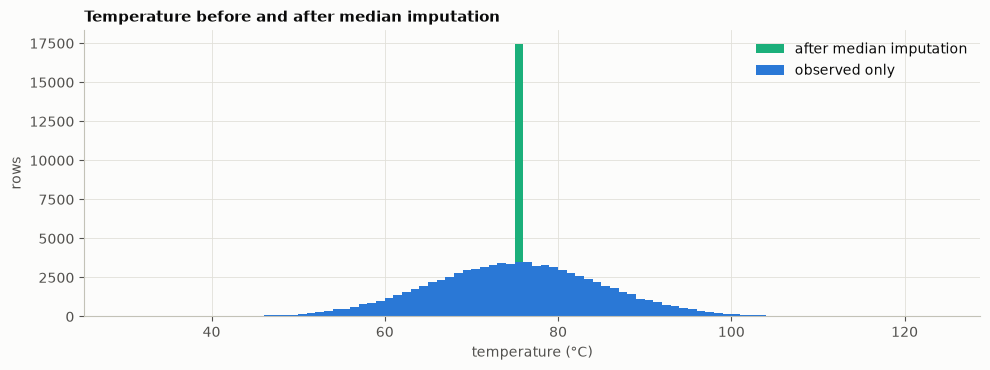

Std before: 10.036  |  Std after: 9.307


In [42]:
df_imputed = df.copy()
df_imputed["temperature_missing"] = df_imputed["temperature"].isna().astype(int)
df_imputed["temperature"] = df_imputed["temperature"].fillna(median_temp)
print(f"Missing temperature after imputation: {df_imputed['temperature'].isna().sum()}")

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(30, 125, 1)
ax.hist(df_imputed["temperature"], bins=bins, color=AQUA, label="after median imputation")
ax.hist(df["temperature"].dropna(), bins=bins, color=BLUE, label="observed only")
ax.set(title="Temperature before and after median imputation", xlabel="temperature (°C)", ylabel="rows")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Std before: {df['temperature'].std():.3f}  |  Std after: {df_imputed['temperature'].std():.3f}")

**Interpretation.** Median imputation puts all 14,000 filled values at one point (the spike at ≈ 75 °C), which
**shrinks the spread** of temperature (standard deviation falls from ~10.0 to ~9.3). This is the known trade-off of
single-value imputation. It is acceptable here because the data are MCAR and no technique does better, and the
`temperature_missing` indicator tells the model which values were filled in.

## 13. Feature engineering recommendations

**Purpose.** Turn the findings into concrete features for the Task 2 pipeline. Each feature is justified by
evidence from this notebook.

| Feature / action | How | Justification (section) |
|------------------|-----|-------------------------|
| `vibration` → absolute value | `vibration.abs()` | Negative values are a sign error; magnitudes match the positive values (4.3). |
| `temperature` imputation | Median, fitted on the training split | MCAR; median is as accurate as KNN/iterative imputation (4.4, 12). |
| `temperature_missing` | 1 if temperature was missing, else 0 | Keeps the information that the value was imputed; some missing values hid > 90 °C readings (12.2). |
| `temp_above_90` | 1 if temperature > 90 | Maintenance rate jumps to 100% above 90 °C; gives linear models the threshold that trees find on their own (7.1, 9.3). |
| `vibration_above_80` | 1 if \|vibration\| > 80 | Same step effect at 80 mm/s (7.1, 9.3). |
| Drop `anomaly_flag`, `downtime_risk`, `machine_status`, `failure_type`, `predicted_remaining_life` | Exclude in the `sensor` feature set | Target leakage / post-failure information (9). Keep only in the `all` comparison set. |
| Drop `timestamp`, `machine_id` | Do not use as features | No temporal or machine-level signal (10, 11). |
| Keep `humidity`, `pressure`, `energy_consumption` (optional) | As-is, standardised for linear models | MI ≈ 0, but harmless; models can confirm their low importance (7.1, 11). |
| Standardise numeric features | `StandardScaler` for linear/distance models | Feature ranges differ widely (6). |

The cell below demonstrates the recommended sensor feature set (the real implementation belongs in the Task 2
`.py` pipeline, not in this notebook).

In [43]:
def build_sensor_features(data: pd.DataFrame, temperature_fill: float) -> pd.DataFrame:
    """Create the recommended sensor-only feature set from raw readings."""
    features = pd.DataFrame(index=data.index)
    features["temperature_missing"] = data["temperature"].isna().astype(int)
    features["temperature"] = data["temperature"].fillna(temperature_fill)
    features["vibration"] = data["vibration"].abs()
    features["humidity"] = data["humidity"]
    features["pressure"] = data["pressure"]
    features["energy_consumption"] = data["energy_consumption"]
    features["temp_above_90"] = (features["temperature"] > 90).astype(int)
    features["vibration_above_80"] = (features["vibration"] > 80).astype(int)
    return features


sensor_features = build_sensor_features(df_raw, temperature_fill=median_temp)
display(sensor_features.head())
display(maintenance_rate(sensor_features.assign(**{TARGET: df_raw[TARGET]}),
                         ["temp_above_90", "vibration_above_80"]))

,temperature_missing,temperature,vibration,humidity,pressure,energy_consumption,temp_above_90,vibration_above_80
0,1,75.0900,28.6500,79.9600,3.7300,2.1600,0,0
1,0,68.1900,57.2800,35.9400,3.6400,0.6900,0,0
2,0,98.9400,50.2000,72.0600,1.0000,2.4900,1,0
3,0,90.9100,37.6500,30.3400,3.1500,4.9600,1,0
4,0,72.3200,40.6900,56.7100,2.6800,0.6300,0,0


rows  maintenance_rate
temp_above_90 vibration_above_80                         
0             0                   92011           12.7200
              1                    2157          100.0000
1             0                    5705          100.0000
              1                     127          100.0000

**Interpretation.** Whenever either engineered threshold flag is 1, the maintenance rate is 100%. When both are 0,
the rate falls to roughly 13%. Those remaining cases come from the failure state and low remaining life, which the
sensors only partly reflect, so this is where the models in Task 2 must do the real predictive work.

## 14. Summary of key findings

### Data quality
1. **100,000 readings, 13 columns, 50 machines, one reading per minute** from 1 Jan to 11 Mar 2025. No duplicates.
2. **Timestamps are day-first (`D/M/YYYY H:MM`)** and must be parsed with that explicit format.
3. **`vibration` has 6,703 (6.7%) negative values caused by a sign error.** Their magnitudes match the positive
   values (KS p ≈ 0.58) and the anomaly label uses the magnitude → **use `|vibration|`**.
4. **`temperature` is missing in 14,000 rows (14%), completely at random (MCAR)** → **median imputation + missing
   indicator**, fitted on the training data only. KNN imputation performs worse and iterative imputation is only
   marginally better, because temperature is independent of the other sensors.
5. **Outliers in temperature/vibration are real high-risk events (100% maintenance at the high end) → keep them.**
6. `downtime_risk` duplicates `anomaly_flag`; `failure_type` only describes failures after they happen and
   is "Normal" for 1,956 failure rows.

### Relationship with the target
7. **Class imbalance ≈ 4 : 1 (19.7% positive)** → accuracy is misleading (80.3% by always predicting "no").
8. **The target is fully determined by derived columns:** `maintenance_required = anomaly_flag OR machine_status == 2
   OR predicted_remaining_life < 20` (0 exceptions in 100,000 rows) → **target leakage**.
9. **`anomaly_flag = temperature > 90 °C OR |vibration| > 80 mm/s`**, and every anomaly has a
   `predicted_remaining_life` below 50 hours, so the derived columns are built from each other.
10. Among the sensors, **temperature is the most important predictor, then vibration**, both with sharp threshold
    effects. **Humidity, pressure, energy consumption, machine ID and time have no relationship with the target.**
11. Readings are **independent over time** (lag-1 autocorrelation ≈ 0, no time or machine effects).

### Implications for the Task 2 pipeline
* **Feature sets:** make the feature set configurable – a leakage-free **`sensor`** set (main) and an **`all`** set
  for comparison only. Report the `all` set's near-perfect score as evidence of leakage, not as model quality.
* **Cleaning:** parse timestamps day-first, take `|vibration|`, impute temperature (median + indicator) inside the
  training pipeline.
* **Splitting:** stratified random train/test split and stratified k-fold cross-validation.
* **Models (at least three):** the threshold-shaped relationships favour tree-based models; a linear model is a
  useful interpretable baseline. Suggested candidates: **Logistic Regression** (baseline, with scaling and threshold
  features), **Random Forest**, and **Gradient Boosting** (e.g. `HistGradientBoostingClassifier`, which also handles
  missing values natively).
* **Metrics:** recall, precision, F1 and PR-AUC for the "maintenance required" class, plus the confusion matrix.
  Recall is prioritised because a missed maintenance case means unscheduled downtime.
* **Expectations:** about 45% of positives come only from the failure state, which no sensor reflects, so a
  leakage-free sensor model has a realistic **recall ceiling well below 100%**. This should be explained, not hidden.